# Can Speculative Crowding Improve Commodity ETF Momentum?

Kang, Rouwenhorst and Tang (2021) show that commodity momentum earns most of its premium when speculators are not already crowded into the trade. We adapt their analysis to 12 commodity ETFs.

**Contribution.** (i) The paper's futures prices are commercial data: we use investable ETFs, which can be downloaded in the notebook. (ii) Our sample includes 2020-2026, after the end of the paper's sample. (iii) The paper dates CFTC positions on the Tuesday they are measured, but they are only published on the Friday: we show what happens when only published positions are used.

**Main results.** With the paper's timing, the low-crowding strategy has a Sharpe ratio of 0.38, against 0.25 for classical momentum, a gap well below the uncertainty on a Sharpe ratio over 11 years. This timing cannot be executed, because CFTC positions are only published on the Friday. Using only published positions, the Sharpe ratio of the low-crowding strategy falls to 0.25, the same as classical momentum.

**References.** Kang, Rouwenhorst and Tang (2021), *Crowding and Factor Returns*, SSRN 3814952. Code: the course package [`skfin`](https://github.com/schampon/skfin) (backtesting, metrics, plots and data loading). Data: [CFTC Commitments of Traders](https://publicreporting.cftc.gov/Commitments-of-Traders/Legacy-Futures-Only/6dca-aqww) and Yahoo Finance.

In [1]:
from urllib.parse import urlencode

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from skfin.backtesting import compute_pnl
from skfin.backtesting_with_cost import average_holding_period
from skfin.dataloaders.cache import CacheManager
from skfin.dataloaders.web_utils import WebUtils
from skfin.datasets import load_yf_returns
from skfin.metrics import drawdown, sharpe_ratio
from skfin.plot import line

START, END = "2010-01-01", "2026-11-01"
CACHE = "data"
N_LEG = 6

# ETF ticker -> CFTC code of the corresponding futures market
MARKETS = {
    "USO": "067651",  # WTI crude oil
    "UNG": "023651",  # natural gas
    "UGA": "111659",  # RBOB gasoline
    "CPER": "085692",  # copper
    "CORN": "002602",  # corn
    "WEAT": "001602",  # wheat
    "SOYB": "005602",  # soybeans
    "CANE": "080732",  # sugar
    "GLD": "088691",  # gold
    "SLV": "084691",  # silver
    "PPLT": "076651",  # platinum
    "PALL": "075651",  # palladium
}

sr = lambda x: sharpe_ratio(x, 52, remove_zeros=False)

## 1. Data

**Returns.** The paper uses nearby futures prices from Commodity Systems Inc., which are not free. We use ETFs instead. Eight hold futures and roll them (USO, UNG, UGA, CPER, CORN, WEAT, SOYB, CANE); four hold the metal (GLD, SLV, PPLT, PALL). ETF returns therefore approximate rolled futures returns, net of fees and with each fund's own roll schedule. We use adjusted prices and compound daily returns from Tuesday to Tuesday to obtain the weekly return of ETF $i$:

$$
r_{i,t} = \prod_{d \in \text{week } t} \left(1 + r^{day}_{i,d}\right) - 1.
$$


**Positions.** The CFTC Legacy, futures-only report gives, each week, the long and short positions of non-commercial traders and the open interest $OI_{i,t}$ of each market. Following equations (2)-(4) of the paper, speculative pressure and crowding are:

$$
Q_{i,t} = \frac{Long_{i,t} - Short_{i,t}}{OI_{i,t}},
\qquad
C_{i,t} = Q_{i,t} - \frac{1}{52}\sum_{k=1}^{52} Q_{i,t-k}.
$$

In [2]:
daily = load_yf_returns(list(MARKETS), start=START, end=END, cache_dir=CACHE)["price_returns"]
ret = daily.add(1).resample("W-TUE").prod(min_count=1).sub(1).loc[:END, list(MARKETS)]


def load_crowding(dataset="6dca-aqww"):
    def download():
        query = {
            "$select": "report_date_as_yyyy_mm_dd as report, cftc_contract_market_code as code, "
            "open_interest_all as oi, noncomm_positions_long_all as l, noncomm_positions_short_all as s",
            "$where": f"cftc_contract_market_code in {tuple(MARKETS.values())} "
            f"and report_date_as_yyyy_mm_dd between '{START}' and '{END}'",
            "$limit": 100000,
        }
        url = f"https://publicreporting.cftc.gov/resource/{dataset}.json?{urlencode(query)}"
        return pd.DataFrame(WebUtils.get_response(url).json())

    raw = CacheManager(CACHE).get_cached_dataframe(f"cot_{dataset}.parquet", download)
    raw = raw.astype({"oi": float, "l": float, "s": float}).assign(report=lambda x: pd.to_datetime(x["report"]))
    q = raw.assign(q=(raw["l"] - raw["s"]) / raw["oi"]).pivot(index="report", columns="code", values="q")
    q = q.rename(columns={v: k for k, v in MARKETS.items()})[list(MARKETS)]
    return q - q.shift(1).rolling(52).mean()


crowding = load_crowding()
pd.DataFrame(
    {
        "first return": ret.apply(lambda x: x.first_valid_index().date()),
        "return (%/yr)": ret.mean() * 5200,
        "vol (%/yr)": ret.std() * np.sqrt(52) * 100,
        "crowding mean": crowding.mean(),
        "crowding std": crowding.std(),
    }
).round(2)

,first return,return (%/yr),vol (%/yr),crowding mean,crowding std
USO,2010-01-05,3.07,36.95,-0.00,0.04
UNG,2010-01-05,-17.97,47.57,0.00,0.05
UGA,2010-01-05,14.25,35.08,-0.00,0.04
CPER,2011-11-22,5.57,22.07,0.00,0.10
CORN,2010-06-15,-0.15,20.42,-0.00,0.11
WEAT,2011-09-20,-8.05,25.35,-0.00,0.08
SOYB,2011-09-20,1.87,16.91,-0.00,0.11
CANE,2011-09-20,-2.64,22.34,-0.01,0.10
GLD,2010-01-05,8.56,16.22,0.00,0.11
SLV,2010-01-05,11.18,31.39,-0.00,0.10


Returns differ widely across funds: UNG loses about 18% a year while UGA gains about 14%. Crowding is centred on zero by construction, with a standard deviation ranging from 0.04 (USO, UGA) to 0.16 (PALL).

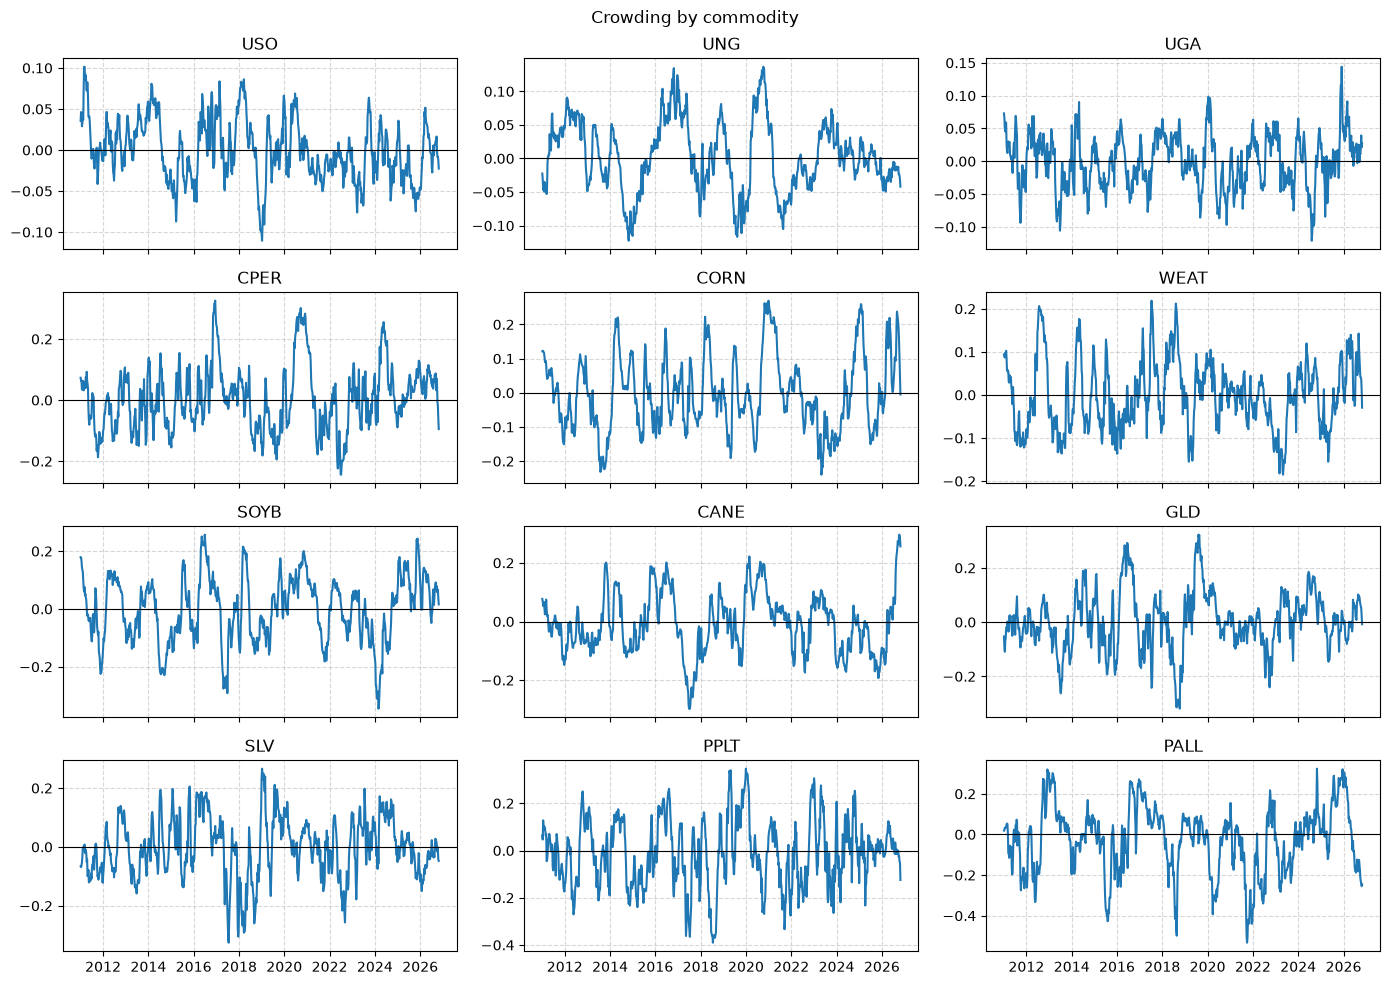

In [3]:
fig, axes = plt.subplots(4, 3, figsize=(14, 10), sharex=True)
for ax, ticker in zip(axes.flat, MARKETS):
    line(crowding[ticker], ax=ax, title=ticker, legend=False, sort=False)
    ax.axhline(0, color="black", lw=0.8)
fig.suptitle("Crowding by commodity")
fig.tight_layout()

## 2. Method

**Momentum.** Each Tuesday we rank the 12 ETFs on their past 52-week return, buy the top 6 and short the bottom 6 with equal weights, and hold for one week (the paper trades 13 against 13):

$$
MOM_{i,t} = \prod_{k=0}^{51}(1 + r_{i,t-k}) - 1,
\qquad
w_{i,t} = \begin{cases} +1/6 & \text{if } i \in L_t \text{ (top 6)} \\ -1/6 & \text{if } i \in S_t \text{ (bottom 6)} \end{cases}
\qquad
R^{MOM}_{t+1} = \sum_{i=1}^{12} w_{i,t}\, r_{i,t+1}.
$$

**Factor crowding.** Following equation (5) of the paper, we average the crowding of the constituents, with a plus sign for longs and a minus sign for shorts:

$$
C^{MOM}_t = \frac{1}{2}\left(\frac{1}{6}\sum_{i \in L_t} C_{i,t} - \frac{1}{6}\sum_{i \in S_t} C_{i,t}\right) = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t}.
$$

**Crowding rule.** As in Figure 2 of the paper, the low-crowding strategy holds the momentum portfolio only when factor crowding is below its average over the previous 156 weeks, and stays in cash otherwise. The high-crowding strategy does the opposite, so the two add up to classical momentum:

$$
\bar C_t = \frac{1}{156}\sum_{k=1}^{156} C^{MOM}_{t-k},
\qquad
e_t = \mathbb{1}_{\{C^{MOM}_t < \bar C_t\}},
$$

$$
R^{LOW}_{t+1} = e_t\, R^{MOM}_{t+1},
\qquad
R^{HIGH}_{t+1} = (1 - e_t)\, R^{MOM}_{t+1}.
$$

**Scope.** As in the paper, we ask whether crowding predicts momentum returns, not whether a fund could trade on it. Positions are dated on the Tuesday they are measured, $C_{i,t}$, before the return of the following week, but the CFTC only publishes them on the Friday. Returns are before transaction costs. Our results are therefore descriptive, not an executable backtest. We come back to this point in Section 3, using only published positions.

Sharpe ratios are annualised with $\sqrt{52}$, and cumulative returns are sums of weekly returns, as in the course.

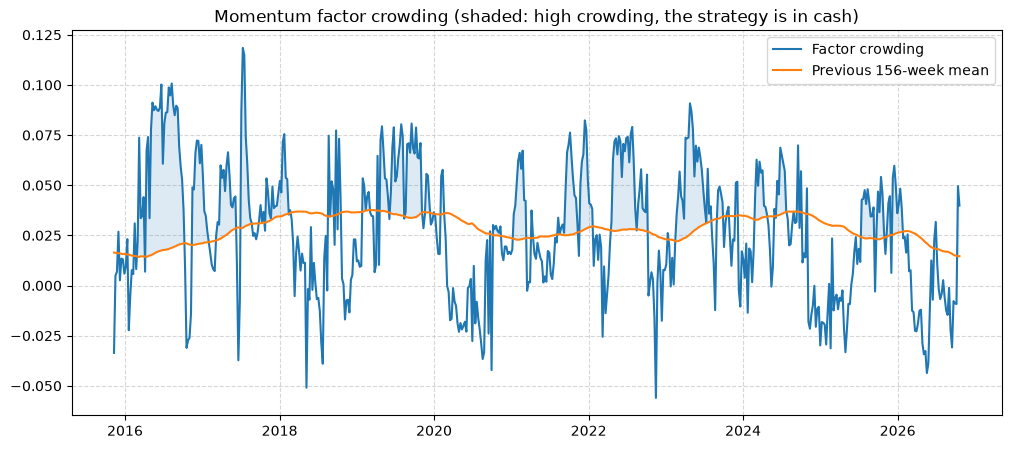

In [4]:
mom = np.log1p(ret).rolling(52).sum().dropna().iloc[:-1]  # same ranking as the 52-week return; the last week has no next-week return
rank = mom.rank(axis=1, ascending=False, method="first")
w = (rank.le(N_LEG).astype(float) - rank.gt(N_LEG).astype(float)) / N_LEG


def factor_crowding(crowding, lag=0):
    aligned = crowding.reindex(ret.index, method="ffill", tolerance=pd.Timedelta(days=6)).shift(lag)
    return 0.5 * (w * aligned.loc[w.index]).sum(axis=1)


def regime(crowding, lag=0, window=156):
    C = factor_crowding(crowding, lag)
    threshold = C.shift(1).rolling(window).mean().dropna()
    return C.loc[threshold.index], threshold, C.loc[threshold.index] < threshold


def book(crowding, lag=0):
    _, _, low = regime(crowding, lag)
    h = w.loc[low.index]
    return {
        "Classical": h,
        "Low crowding": h.mul(low.astype(float), axis=0),
        "High crowding": h.mul((~low).astype(float), axis=0),
    }


def pnl(h):
    return compute_pnl(h.reindex(ret.index), ret, 1).reindex(h.index + pd.Timedelta(weeks=1))


def report(strategies):
    return pd.DataFrame(
        {
            name: {
                "Sharpe": sr(pnl(h)),
                "return (%/yr)": pnl(h).mean() * 5200,
                "vol (%/yr)": pnl(h).std() * np.sqrt(52) * 100,
                "max drawdown (%)": drawdown(pnl(h), return_in_risk_unit=False).min() * 100,
                "weeks invested (%)": h.abs().sum(axis=1).gt(0).mean() * 100,
                "holding period (weeks)": average_holding_period(h),
            }
            for name, h in strategies.items()
        }
    ).T.round(2)


C, threshold, low = regime(crowding)
fig, ax = plt.subplots(figsize=(12, 5))
line(
    pd.DataFrame({"Factor crowding": C, "Previous 156-week mean": threshold}),
    ax=ax, sort=False, loc="best", title="Momentum factor crowding (shaded: high crowding, the strategy is in cash)",
)
ax.fill_between(C.index, C, threshold, where=~low, alpha=0.15);

## 3. Results

### Performance

In [5]:
report(book(crowding))

,Sharpe,return (%/yr),vol (%/yr),max drawdown (%),weeks invested (%),holding period (weeks)
Classical,0.25,5.06,20.52,-37.64,100.00,14.48
Low crowding,0.38,5.81,15.25,-25.58,50.87,4.62
High crowding,-0.05,-0.75,13.73,-58.57,49.13,4.62


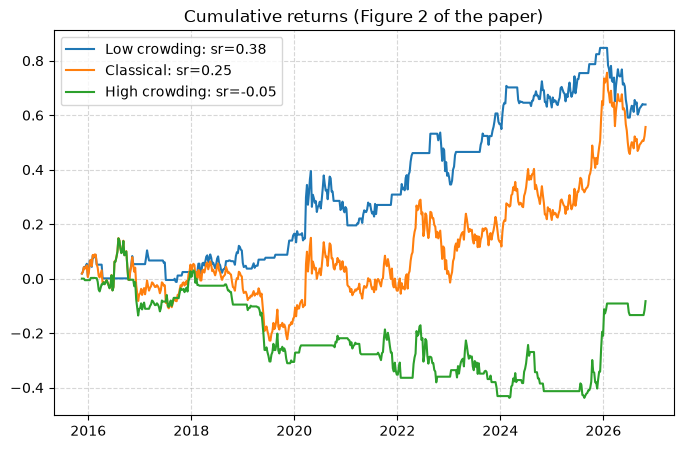

In [6]:
pnls = {k: pnl(h) for k, h in book(crowding).items()}
line({f"{k}: sr={sr(v):.2f}": v for k, v in pnls.items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns (Figure 2 of the paper)")

Classical momentum split by crowding regime (in % of return):

In [7]:
(pnl(w.loc[low.index]) * 100).groupby(np.where(low, "Low crowding", "High crowding")).agg(
    weeks="size", mean_weekly="mean", total="sum"
).round(3)

,weeks,mean_weekly,total
High crowding,281,-0.029,-8.259
Low crowding,291,0.220,63.930


### Can this be executed?

The results above follow the timing of the paper: the decision taken on Tuesday $t$ uses the positions measured on that same Tuesday, $C_{i,t}$. The paper describes the report as published on Tuesday (its Section 2). In practice, the CFTC measures positions at the close on Tuesday and releases them on Friday at 15:30 New York time. Investors therefore do not know $C_{i,t}$ on the day of the decision, and Figure 2 cannot be executed as such: it shows a link between crowding and subsequent returns, not a tradable rule.

We measure what this timing is worth by replacing $C_{i,t}$ with the latest report that is public on Tuesday $t$, the one measured a week earlier (lag 1):

$$
C^{MOM}_t = \frac{1}{2}\sum_{i=1}^{12} w_{i,t}\, C_{i,t-1}.
$$

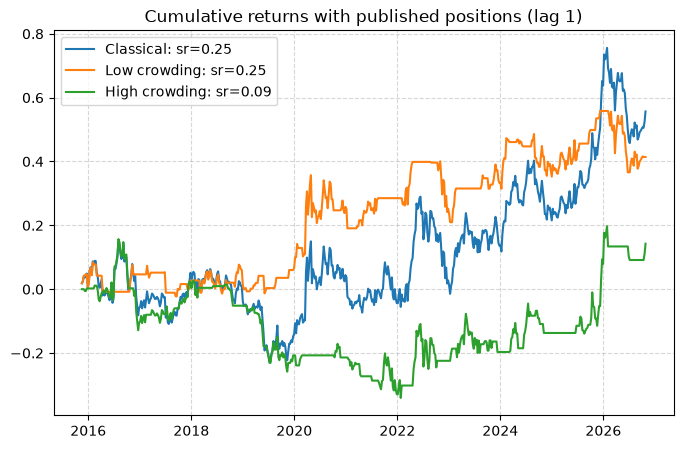

In [8]:
line({f"{k}: sr={sr(pnl(h)):.2f}": pnl(h) for k, h in book(crowding, lag=1).items()}, cumsum=True, legend_sharpe_ratio=False, loc="best", title="Cumulative returns with published positions (lag 1)")

### Reading of the results

- **Same shape as the paper.** With the paper's timing, momentum earns more after low crowding than after high crowding: 64% against -8% in cumulative returns.
- **Not executable as such.** With published positions, the gap narrows to 41% against 14%, and the low-crowding strategy has a Sharpe ratio of 0.25, the same as classical momentum. The paper documents a link between crowding and subsequent momentum returns, but with these data this link does not give an investor a better strategy than simple momentum.

## 4. Machine learning: momentum, risk, liquidity, macro and seasonality

We compare classical momentum, Ridge and XGBoost **without crowding**. The 12 ETFs, features and long-six / short-six portfolio rule are the same across models.

Following Chapters 4 and 7 of the course, we use `skfin.Backtester` with a **156-week rolling training window**, weekly refitting (`test_size=1`) and `ParameterSampler` for model selection. Hyperparameters are selected on the early walk-forward period only; the same rolling procedure is then evaluated from 2019 onward.

In [ ]:
from io import StringIO

import yfinance as yf
from pathlib import Path
import hashlib

from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import ParameterSampler
from sklearn.base import BaseEstimator
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from skfin.backtesting import Backtester

TRAIN_WEEKS = 156
COST_BPS = 5
ETFS = list(MARKETS)

GROUPS = {
    "USO": "Energy", "UNG": "Energy", "UGA": "Energy",
    "CPER": "Industrial metal",
    "CORN": "Agriculture", "WEAT": "Agriculture",
    "SOYB": "Agriculture", "CANE": "Agriculture",
    "GLD": "Precious metal", "SLV": "Precious metal",
    "PPLT": "Precious metal", "PALL": "Precious metal",
}


def load_extra_data():
    def yahoo():
        raw = yf.download(ETFS, start=START, end=END,
                          auto_adjust=False, progress=False, threads=False)
        if "Close" not in raw.columns.get_level_values(0):
            raw = raw.swaplevel(0, 1, axis=1)
        return pd.concat({
            "Close": raw["Close"].reindex(columns=ETFS),
            "Volume": raw["Volume"].reindex(columns=ETFS),
        }, axis=1).sort_index()

    def fred():
        series = {}
        for name in ("VIXCLS", "DTWEXBGS", "DFII10", "T10YIE", "T10Y2Y"):
            url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={name}"
            data = pd.read_csv(StringIO(WebUtils.get_response(url).text))
            series[name] = pd.Series(
                pd.to_numeric(data[name], errors="coerce").to_numpy(),
                index=pd.to_datetime(data.iloc[:, 0]),
            )
        return pd.DataFrame(series).sort_index()

    cache = CacheManager(CACHE)
    prices = cache.get_cached_dataframe("ml_yahoo_ohlcv.parquet", yahoo)
    macro_daily = cache.get_cached_dataframe("ml_fred_macro.parquet", fred)
    return prices, macro_daily


prices, macro_daily = load_extra_data()
close, volume = prices["Close"], prices["Volume"]

### 4.1 Features and target

All returns-based predictors use the same weekly ETF returns as classical momentum. Yahoo provides trading volume; FRED provides macro indicators, aligned to observations at least seven calendar days old. This does not guarantee point-in-time historical FRED values.

| Family | Features | Rationale |
|---|---|---|
| Momentum | `Mom1`, `Mom4`, `Mom13`, `Mom26`, `Mom52`, `MomAcceleration`, `RelMom13`, `MarketMom4`, `Mom13_HistZ` | Trend strength, short-term reversal, acceleration, unusual momentum and common-market conditions |
| Risk | `Vol4`, `Vol13`, `Vol52`, `DownsideVol13`, `RelativeVol13`, `Drawdown13` | Short/long-term volatility, downside risk and relative risk |
| Liquidity | `LogDollarVolume4`, `DollarVolumeZ13` | Trading activity and unusually high/low liquidity |
| Macro | `VIX`, `VIXChange4`, `DollarChange4`, `RealYield10Y`, `Breakeven10Y`, `YieldSlope` | Risk aversion, dollar strength and US rates/inflation conditions |
| Seasonality | `SeasonSin`, `SeasonCos` | Smooth time-of-year effects |
| Identity | `Group_*` (4) and `ETF_*` (12) | Distinguish commodity groups and individual ETFs |

`MomAcceleration` compares the last four-week return with the four-week equivalent implied by 13-week momentum. `Mom13_HistZ` compares current momentum with the **previous 26 weeks** (`shift(1)`), avoiding future information. `Mom1` is kept but not its exact duplicate `Reversal_1w = -Mom1`.

**Target:** next-week absolute return, $y_{i,t}=r_{i,t+1}$. No CFTC variables enter this benchmark.

In [ ]:
log_ret = np.log1p(ret)
mom4 = np.expm1(log_ret.rolling(4).sum())
mom13 = np.expm1(log_ret.rolling(13).sum())
mom26 = np.expm1(log_ret.rolling(26).sum())
mom52 = np.expm1(log_ret.rolling(52).sum())

past_mom13 = mom13.shift(1).rolling(26, min_periods=26)
vol13 = ret.rolling(13).std()

f = {
    "Mom1": ret,
    "Mom4": mom4,
    "Mom13": mom13,
    "Mom26": mom26,
    "Mom52": mom52,
    "MomAcceleration": mom4 - np.expm1(np.log1p(mom13) * 4 / 13),
    "RelMom13": mom13.sub(mom13.mean(axis=1), axis=0),
    "MarketMom4": pd.DataFrame({e: mom4.mean(axis=1) for e in ETFS}),
    "Mom13_HistZ": (mom13 - past_mom13.mean()) / past_mom13.std().replace(0, np.nan),
    "Vol4": ret.rolling(4).std(),
    "Vol13": vol13,
    "Vol52": ret.rolling(52).std(),
    "DownsideVol13": np.sqrt(ret.clip(upper=0).pow(2).rolling(13).mean()),
    "RelativeVol13": vol13.div(vol13.median(axis=1).replace(0, np.nan), axis=0),
}

nav = (1 + ret).cumprod()
f["Drawdown13"] = nav.rolling(13).apply(
    lambda x: (x / np.maximum.accumulate(x) - 1).min(), raw=True
)

# Yahoo: traded dollar volume. Weekly aggregation uses only historical trading days.
dollar_volume = close * volume
weekly_dollar = dollar_volume.resample("W-TUE").sum(min_count=1).reindex(ret.index)
log_dollar = np.log1p(weekly_dollar)
f["LogDollarVolume4"] = log_dollar.rolling(4).mean()
f["DollarVolumeZ13"] = (
    (log_dollar - log_dollar.rolling(13).mean())
    / log_dollar.rolling(13).std().replace(0, np.nan)
)

# FRED: last available observation for each series, at least 7 days old.
lagged_dates = ret.index - pd.Timedelta(days=7)
macro = pd.DataFrame({
    name: macro_daily[name].dropna().reindex(
        lagged_dates, method="ffill", tolerance=pd.Timedelta(days=14)
    ).to_numpy()
    for name in ("VIXCLS", "DTWEXBGS", "DFII10", "T10YIE", "T10Y2Y")
}, index=ret.index)

# Same macro signal for all 12 ETFs; XGBoost can interact with their group.
def repeat(s):
    return pd.DataFrame({ticker: s for ticker in ETFS})

macro_features = {
    "VIX": macro["VIXCLS"],
    "VIXChange4": macro["VIXCLS"].diff(4),
    "DollarChange4": macro["DTWEXBGS"].pct_change(4, fill_method=None),
    "RealYield10Y": macro["DFII10"],
    "Breakeven10Y": macro["T10YIE"],
    "YieldSlope": macro["T10Y2Y"],
}
f.update({name: repeat(s) for name, s in macro_features.items()})

# Known calendar information: year-end and year-start are adjacent.
day = ret.index.dayofyear
f["SeasonSin"] = repeat(pd.Series(np.sin(2 * np.pi * day / 365.25), index=ret.index))
f["SeasonCos"] = repeat(pd.Series(np.cos(2 * np.pi * day / 365.25), index=ret.index))

for group in sorted(set(GROUPS.values())):
    f[f"Group_{group}"] = pd.DataFrame(
        {ticker: float(GROUPS[ticker] == group) for ticker in ETFS},
        index=ret.index,
    )

for asset in ETFS:
    f[f"ETF_{asset}"] = pd.DataFrame(
        {ticker: float(ticker == asset) for ticker in ETFS},
        index=ret.index,
    )

target = ret.shift(-1).reindex(w.index)[ETFS]
features = pd.concat({
    ticker: pd.DataFrame({name: values[ticker] for name, values in f.items()})
    for ticker in ETFS
}, axis=1).reindex(target.index).replace([np.inf, -np.inf], np.nan)

complete = features.notna().all(axis=1) & target.notna().all(axis=1)
if not complete.any():
    raise ValueError("No complete week: check volume and macro data coverage.")
first = complete[complete].index[0]
features, target = features.loc[first:], target.loc[first:]
if not features.notna().all().all() or not target.notna().all().all():
    missing = features.isna().T.groupby(level=1).sum().sum(axis=1).sort_values(ascending=False)
    raise ValueError(f"Missing observations after {first:%Y-%m-%d}:\n{missing[missing > 0]}")
if len(features) <= TRAIN_WEEKS + 1:
    raise ValueError("Insufficient history for the rolling training window.")

START_ML = features.index[TRAIN_WEEKS].strftime("%Y-%m-%d")
print(f"First complete week: {first:%Y-%m-%d}")
print(f"First walk-forward prediction: {START_ML}")
print(f"{len(ETFS)} ETFs, {len(f)} features per ETF ({len(f)-16} numerical + 4 groups + 12 ETF indicators)")
print(f"Volume coverage since 2019: {volume.loc['2019':].notna().mean().mean():.1%}")

### 4.2 Models

The model pools the weekly observations from all 12 ETFs, forecasts **next-week absolute returns**, then goes long the six highest forecasts and short the other six. `skfin.Backtester` handles the weekly rolling fit/predict steps; `RankModel` only converts forecasts into the same 6/6 portfolio as Section 2.

Ridge is standardized **within each training window**. XGBoost uses squared-error regression. We do not impose arbitrary values for its main complexity, sampling and regularization hyperparameters: these are selected below.

In [ ]:
class RankModel(BaseEstimator):
    def __init__(self, method="ridge", params=None):
        self.method = method
        self.params = params

    def fit(self, X, y):
        self.n_assets_ = y.shape[1]
        self.n_features_ = X.shape[1] // self.n_assets_
        params = self.params or {}
        if self.method == "ridge":
            self.model_ = make_pipeline(StandardScaler(), Ridge(**params))
        elif self.method == "xgboost":
            self.model_ = XGBRegressor(
                **params, objective="reg:squarederror", tree_method="hist",
                random_state=42, n_jobs=1,
            )
        else:
            raise ValueError("Unknown model")
        self.model_.fit(X.reshape(-1, self.n_features_), y.reshape(-1))
        return self

    def forecast(self, X):
        return self.model_.predict(X.reshape(-1, self.n_features_)).reshape(-1, self.n_assets_)

    def predict(self, X):
        forecast = self.forecast(X)
        order = np.argsort(-forecast, axis=1, kind="stable")
        weights = np.full_like(forecast, -1 / N_LEG, dtype=float)
        np.put_along_axis(weights, order[:, :N_LEG], 1 / N_LEG, axis=1)
        return weights

### 4.3 Hyperparameter selection — early walk-forward validation

As in Chapter 7, we draw configurations with `ParameterSampler` and rank them by their **validation Sharpe**. Every trial runs the same weekly `Backtester(max_train_size=156, test_size=1)`:

- **Training at each date:** the preceding 156 labelled weeks.
- **Validation:** from the first available walk-forward prediction through **2018-12-25**.
- **Final test:** **2019–2026**, never used to select hyperparameters.

Unlike a fixed train/validation split, validation is itself a sequence of one-week out-of-sample predictions. Old validation observations can subsequently be used for training once they are in the past. We also tune Ridge's `alpha`. Results are cached under a fingerprint of the validation inputs, as in the course.

In [ ]:
VALID_END = "2018-12-25"
TEST_START = "2019-01-01"
N_TRIALS = 24

if pd.Timestamp(START_ML) >= pd.Timestamp(VALID_END):
    raise ValueError(f"Not enough early data: first prediction is {START_ML}")
if features.index[-1] < pd.Timestamp(TEST_START):
    raise ValueError("No 2019+ observations for the final test.")

param_distributions = {
    "max_depth": randint(1, 5),
    "n_estimators": randint(50, 251),
    "learning_rate": loguniform(0.01, 0.15),
    "min_child_weight": randint(1, 21),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "reg_alpha": loguniform(1e-6, 0.1),
    "reg_lambda": loguniform(0.01, 50),
    "gamma": uniform(0, 0.002),
}


def validation_sharpe(method, params):
    estimator = RankModel(method, params)
    backtest = Backtester(
        estimator, max_train_size=TRAIN_WEEKS, test_size=1,
        pred_lag=1, start_date=START_ML, end_date=VALID_END,
    )
    backtest.train(features, target, ret)
    holdings = backtest.h_.loc[START_ML:VALID_END, ETFS]
    return sr(pnl(holdings).loc[:VALID_END])


# Cache key changes if the validation dataset or target changes.
training = features.loc[:VALID_END]
labels = target.loc[:VALID_END]
digest = hashlib.sha256(
    pd.util.hash_pandas_object(training, index=True).values.tobytes()
    + pd.util.hash_pandas_object(labels, index=True).values.tobytes()
).hexdigest()[:12]
search_dir = Path(CACHE) / "ml_hyperparameters"
search_dir.mkdir(parents=True, exist_ok=True)


def search_parameters(method, distributions, n_trials):
    filename = search_dir / f"v2_{method}_{TRAIN_WEEKS}_{VALID_END}_{digest}_{n_trials}.csv"
    if filename.exists():
        results = pd.read_csv(filename)
    else:
        scores = []
        candidates = ParameterSampler(distributions, n_iter=n_trials, random_state=42)
        for i, params in enumerate(candidates, 1):
            score = validation_sharpe(method, params)
            scores.append({**params, "Sharpe": score})
            print(f"{method}: {i}/{n_trials}", end="\r")
        results = pd.DataFrame(scores)
        results.to_csv(filename, index=False)
        print()
    return results.sort_values("Sharpe", ascending=False).reset_index(drop=True)


ridge_results = search_parameters("ridge", {"alpha": loguniform(0.1, 1000)}, 6)
xgb_results = search_parameters("xgboost", param_distributions, N_TRIALS)

ridge_params = {"alpha": float(ridge_results.loc[0, "alpha"])}
integer_params = {"max_depth", "n_estimators", "min_child_weight"}
xgb_params = {
    name: int(xgb_results.loc[0, name]) if name in integer_params
    else float(xgb_results.loc[0, name])
    for name in param_distributions
}

print("Validation Sharpe (Ridge):", round(ridge_results.loc[0, "Sharpe"], 3))
print("Validation Sharpe (XGBoost):", round(xgb_results.loc[0, "Sharpe"], 3))
print("Selected Ridge params:", ridge_params)
print("Selected XGBoost params:", xgb_params)
display(xgb_results.head(5).round(4))

### 4.4 Weekly rolling backtest — same method, selected parameters

We now **freeze** the selected parameters and run the professor's `Backtester` over the full available history. Each week's model is fitted on the preceding **156 weeks** and predicts only the next week (`test_size=1`, `pred_lag=1`).

We report **validation (through 2018)** and **test (2019 onward)** separately. Validation Sharpe is biased upward by parameter selection; test Sharpe is a more independent check. Both periods are composed of genuine one-week walk-forward predictions.

In [ ]:
strategies = {"Classical": w.loc[START_ML:features.index[-1]]}
backtests = {}

for name, method, params in (
    ("Ridge", "ridge", ridge_params),
    ("XGBoost", "xgboost", xgb_params),
):
    backtest = Backtester(
        RankModel(method, params), max_train_size=TRAIN_WEEKS,
        test_size=1, pred_lag=1, start_date=START_ML,
    )
    backtest.train(features, target, ret)
    backtests[name] = backtest
    strategies[name] = backtest.h_.loc[START_ML:features.index[-1], ETFS]

common = strategies["XGBoost"].index
strategies = {name: h.loc[common] for name, h in strategies.items()}
pnls_ml = {name: pnl(h) for name, h in strategies.items()}

periods = {
    "Validation": slice(START_ML, VALID_END),
    "Test": slice(TEST_START, None),
}
performance = pd.DataFrame({
    period: {name: sr(returns.loc[dates]) for name, returns in pnls_ml.items()}
    for period, dates in periods.items()
})
display(performance.round(3))

line({f"{name}: sr={sr(value.loc[TEST_START:]):.2f}": value.loc[TEST_START:]
      for name, value in pnls_ml.items()},
     cumsum=True, legend_sharpe_ratio=False, loc="best",
     title="Out-of-sample backtest, 2019–2026 (no crowding)")

In [ ]:
pnls_net = {}
for name, h in strategies.items():
    turnover = h.diff().fillna(h).abs().sum(axis=1)
    turnover.index = turnover.index + pd.Timedelta(weeks=1)
    pnls_net[name] = pnls_ml[name] - COST_BPS / 10000 * turnover.reindex(pnls_ml[name].index).fillna(0)

pd.DataFrame({
    name: {
        "Test gross Sharpe": sr(pnls_ml[name].loc[TEST_START:]),
        "Test net Sharpe": sr(pnls_net[name].loc[TEST_START:]),
    }
    for name in strategies
}).T.round(3)

### 4.5 Forecast diagnostics — 2019 onward

We calculate RMSE and weekly cross-sectional Rank IC only on the final test, without using them to change the selected hyperparameters.

In [ ]:
diagnostics = {}
for name, backtest in backtests.items():
    dates = strategies[name].loc[TEST_START:].index
    forecast = pd.DataFrame(
        np.vstack([model.forecast(features.loc[[date]].to_numpy())
                   for date, model in zip(backtest.h_.index, backtest.estimators_)]),
        index=backtest.h_.index, columns=ETFS,
    ).loc[dates]
    actual = target.loc[dates]
    diagnostics[name] = {
        "RMSE": np.sqrt(((forecast - actual) ** 2).stack().mean()),
        "Rank IC": forecast.corrwith(actual, axis=1, method="spearman").mean(),
    }
    assert (strategies[name].gt(0).sum(axis=1) == N_LEG).all()
    assert (strategies[name].lt(0).sum(axis=1) == N_LEG).all()
    assert np.allclose(strategies[name].sum(axis=1), 0)

pd.DataFrame(diagnostics).T.round(4)

## 5. Feature ablation — does removing noisy predictors help?

We compare four **nested feature sets**, always using the same 12 ETFs, target, 156-week rolling window, weekly refitting (`skfin.Backtester`, `test_size=1`) and long-six / short-six rule.

| Version | Removed from the 41-column baseline | Features per ETF |
|---|---|---:|
| Full | Nothing | 41 |
| No groups | Four `Group_*` indicators (ETF identity is retained) | 37 |
| No short-term risk | Also `Vol4` and `DownsideVol13` | 35 |
| No volume Z | Also `DollarVolumeZ13` | 34 |

**Controlled comparison.** We reuse the Ridge and XGBoost hyperparameters selected on the **full feature set**, using validation observations ending in 2018. We do **not retune them** after removing features: that isolates the impact of the features rather than mixing it with hyperparameter changes. Each model is still fitted anew every week.

The validation period (through 2018) is used to compare configurations. The 2019–2026 results are reported separately as a diagnostic, **not used to select features**. Earlier experiments have already inspected some of those years, so this is not a pristine holdout. No crowding information is used.

In [ ]:
ablations = {
    "Full": [],
    "No groups": [name for name in f if name.startswith("Group_")],
    "No short-term risk": [name for name in f if name.startswith("Group_")]
        + ["Vol4", "DownsideVol13"],
    "No volume Z": [name for name in f if name.startswith("Group_")]
        + ["Vol4", "DownsideVol13", "DollarVolumeZ13"],
}

# Keep the same column order and identical weeks in every experiment.
feature_sets = {
    name: features.drop(columns=dropped, level=1)
    for name, dropped in ablations.items()
}

for name, X in feature_sets.items():
    assert X.index.equals(features.index)
    assert X.notna().all().all()
    assert X.shape[1] % len(ETFS) == 0

pd.DataFrame({
    "Features per ETF": {name: X.shape[1] // len(ETFS) for name, X in feature_sets.items()},
    "Removed": {name: ", ".join(dropped) or "None" for name, dropped in ablations.items()},
})

### 5.1 Same rolling backtest for every feature set

We use **exactly the same** `ridge_params` and `xgb_params`, previously selected before 2019. The unmodified full-model backtests from Section 4 are reused, avoiding duplicate training. The six remaining models are refitted weekly with `Backtester` on the same dates.

We compare **validation Sharpe, test Sharpe, test Rank IC (raw forecasts)** and **test RMSE**. Rank IC is computed from predicted returns, **not** from binary long/short weights.

In [ ]:
def forecast_metrics(backtest, X):
    dates = backtest.h_.index
    forecast = pd.DataFrame(
        np.vstack([
            model.forecast(X.loc[[date]].to_numpy())
            for date, model in zip(dates, backtest.estimators_)
        ]),
        index=dates, columns=ETFS,
    ).loc[TEST_START:]
    actual = target.loc[forecast.index]
    return (
        float(np.sqrt((forecast - actual).pow(2).stack().mean())),
        float(forecast.corrwith(actual, axis=1, method="spearman").mean()),
    )

comparison = []
returns = {}
for name, X in feature_sets.items():
    returns[name] = {}
    for model_name, method, params in (
        ("Ridge", "ridge", ridge_params),
        ("XGBoost", "xgboost", xgb_params),
    ):
        print(f"{name} / {model_name}")
        if name == "Full":
            bt = backtests[model_name]
            r = pnls_ml[model_name]
        else:
            bt = Backtester(
                RankModel(method, params), max_train_size=TRAIN_WEEKS,
                test_size=1, pred_lag=1, start_date=START_ML,
            )
            bt.train(X, target, ret)
            h = bt.h_.loc[strategies["Classical"].index, ETFS]
            assert (h.gt(0).sum(axis=1) == N_LEG).all()
            assert (h.lt(0).sum(axis=1) == N_LEG).all()
            r = pnl(h)
        assert r.index.equals(pnls_ml["Classical"].index)
        rmse, ic = forecast_metrics(bt, X)
        returns[name][model_name] = r
        comparison.append({
            "Features": name,
            "Model": model_name,
            "Number": X.shape[1] // len(ETFS),
            "Validation Sharpe": sr(r.loc[:VALID_END]),
            "Test Sharpe": sr(r.loc[TEST_START:]),
            "Test Rank IC": ic,
            "Test RMSE": rmse,
        })
        if name != "Full":
            del bt

comparison = pd.DataFrame(comparison).set_index(["Features", "Model"])
display(comparison.round(4))

### 5.2 Visual comparison

All curves use the **same weeks** from 2019 onward. We include classical momentum as the reference. Differences between ablations can arise from model estimation noise; neither feature importance nor the highest test Sharpe alone proves a feature is helpful.

In [ ]:
for model_name in ("Ridge", "XGBoost"):
    curves = {"Classical": pnls_ml["Classical"].loc[TEST_START:]}
    curves.update({name: returns[name][model_name].loc[TEST_START:]
                   for name in ablations})
    line(curves, cumsum=True, legend_sharpe_ratio=False, loc="best",
         title=f"{model_name}: feature ablation (2019–2026)")

**Next step: speculative crowding.** Add CFTC data to the same features and compare on exactly the same weeks, with the same 156-week rolling procedure and hyperparameter-selection protocol. In particular, CFTC observations dated Tuesday must not enter features until they were published on Friday.

**Limitations.** An ETF universe with full 52-week histories starts later than 2010. The FRED series are lagged seven days but their historical revisions are not strictly point-in-time. Tuesday-close features imply an idealized execution convention; practical trading would execute after the closing data become available. Transaction costs of 5 bps per unit traded weight are illustrative. Because 2023–2026 results have already been inspected in earlier experiments, even the final 2019–2026 backtest is not a pristine untouched holdout with respect to our feature-design choices.